# 1854 Cholera Advanced2: nearest sites, ties and buildings

**PHI outbreak investigations · 20–30 minutes · original browser companion**

An original PHI-Case-Studies browser companion compares 35 sampled nearest-site assignments with six invented building centroids, preserving ties and an outside-domain record instead of claiming exact polygons or population coverage.

**Learning question:** What changes when a nearest-site rule preserves boundary ties and an outside-domain building instead of forcing a winner?

**Data status:** original synthetic teaching fixture; no historical measurements, real patient records, source map or external data requests. This bounded companion runs with standard-library Python and IPython in the atlas Lab. Linked source courses have their own rights and runtimes.


## Predict before running

Continue from [Advanced1](../cholera-1854-advanced-1/index.ipynb), but change the question from network cost to nearest straight-line seed. For each integer grid centre x=0..6, y=0..4, compare squared Euclidean distances to A=(1,1) and B=(5,1). Squared distance preserves the comparison without a square root. Keep equal distances as **tie**. Exact comparison here uses finite integer coordinates. Fractional coordinates or a finer-grid extension need an explicit numerical policy for equality; this fixture chooses none for those extensions. For six invented building centroids, first check the inclusive declared domain [0,6] × [0,4]; o=(8,2) stays **outside**. Predict the vertical tie column and the effect of moving B left one unit.

Write a prediction and an assumption. Run cells in order with **Shift+Enter** or **Run → Run All Cells**. The first code cell supplies local SVG display helpers; the next performs the calculation. Every figure has a title/description and printed values as a text alternative. Allow up to 60 seconds per cell on first runtime load; the fixture calculation normally takes seconds and needs no installs, account or credentials.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Invented pump seeds, planar units: {'A': (1, 1), 'B': (5, 1)} ; inclusive domain: (0, 6, 0, 4)
Grid samples / 35: {'A': 15, 'B': 15, 'tie': 5, 'outside': 0}
Building centroids / 6: {'A': 2, 'B': 2, 'tie': 1, 'outside': 1}
Each building: {'a': 'A', 'b': 'A', 'c': 'B', 'd': 'B', 't': 'tie', 'o': 'outside'}
Exact squared-distance ties use this fixture's finite integer coordinates; fractional/finer-grid extensions need an explicit numerical policy.
Samples are not area; buildings are not people or a population denominator.


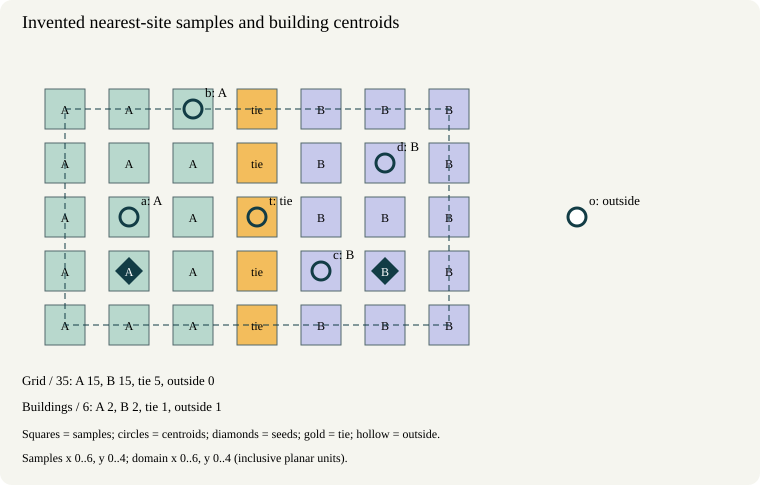

In [2]:
# A finite sampled nearest-site exercise, not an exact Voronoi polygon construction.
pumps = {'A': (1, 1), 'B': (5, 1)}
domain = (0, 6, 0, 4)  # inclusive x minimum/maximum, y minimum/maximum; planar units
samples = [(x, y) for y in range(5) for x in range(7)]
buildings = {'a': (1, 2), 'b': (2, 4), 'c': (4, 1),
             'd': (5, 3), 't': (3, 2), 'o': (8, 2)}

def nearest_site(point, sites, bounds):
    x, y = point
    xmin, xmax, ymin, ymax = bounds
    if not (xmin <= x <= xmax and ymin <= y <= ymax):
        return 'outside'
    distances = {name: (x-px)**2 + (y-py)**2 for name, (px, py) in sites.items()}
    minimum = min(distances.values())
    winners = [name for name, distance in distances.items() if distance == minimum]
    return winners[0] if len(winners) == 1 else 'tie'

grid_membership = {point: nearest_site(point, pumps, domain) for point in samples}
building_membership = {name: nearest_site(point, pumps, domain) for name, point in buildings.items()}
grid_counts = {label: sum(value == label for value in grid_membership.values()) for label in ['A', 'B', 'tie', 'outside']}
building_counts = {label: sum(value == label for value in building_membership.values()) for label in ['A', 'B', 'tie', 'outside']}
print('Invented pump seeds, planar units:', pumps, '; inclusive domain:', domain)
print(f'Grid samples / {len(samples)}:', grid_counts)
print(f'Building centroids / {len(buildings)}:', building_counts)
print('Each building:', building_membership)
print("Exact squared-distance ties use this fixture's finite integer coordinates; fractional/finer-grid extensions need an explicit numerical policy.")
print('Samples are not area; buildings are not people or a population denominator.')

colors = {'A': '#b8d8cd', 'B': '#c7c9eb', 'tie': '#f3bd5c', 'outside': '#ffffff'}
def project(point):
    x, y = point
    return 65 + x * 64, 325 - y * 54
body = '<text x="22" y="28" font-size="18">Invented nearest-site samples and building centroids</text>'
for point, membership in grid_membership.items():
    x, y = project(point)
    body += f'<rect x="{x-20}" y="{y-20}" width="40" height="40" fill="{colors[membership]}" stroke="#52676b"/>'
    body += f'<text x="{x}" y="{y+5}" text-anchor="middle" font-size="12">{escape(membership)}</text>'
xmin, xmax, ymin, ymax = domain
left, top = project((xmin, ymax))
right, bottom = project((xmax, ymin))
body += f'<rect id="domain-frame" x="{left}" y="{top}" width="{right-left}" height="{bottom-top}" fill="none" stroke="#123c45" stroke-dasharray="6 4"/>'
for name, point in buildings.items():
    x, y = project(point)
    membership = building_membership[name]
    body += f'<circle cx="{x}" cy="{y}" r="9" fill="{colors[membership]}" stroke="#123c45" stroke-width="3"/>'
    body += f'<text x="{x+12}" y="{y-12}" font-size="13">{escape(name)}: {escape(membership)}</text>'
for name, point in pumps.items():
    x, y = project(point)
    body += f'<path d="M{x} {y-14}L{x+14} {y}L{x} {y+14}L{x-14} {y}Z" fill="#123c45"/><text x="{x}" y="{y+5}" text-anchor="middle" fill="white" font-size="12">{escape(name)}</text>'
body += f'<text x="22" y="385" font-size="13">Grid / {len(samples)}: A {grid_counts["A"]}, B {grid_counts["B"]}, tie {grid_counts["tie"]}, outside {grid_counts["outside"]}</text>'
body += f'<text x="22" y="411" font-size="13">Buildings / {len(buildings)}: A {building_counts["A"]}, B {building_counts["B"]}, tie {building_counts["tie"]}, outside {building_counts["outside"]}</text>'
body += '<text x="22" y="438" font-size="12">Squares = samples; circles = centroids; diamonds = seeds; gold = tie; hollow = outside.</text>'
sample_x = [point[0] for point in samples]
sample_y = [point[1] for point in samples]
body += f'<text x="22" y="462" font-size="12">Samples x {min(sample_x):g}..{max(sample_x):g}, y {min(sample_y):g}..{max(sample_y):g}; domain x {xmin:g}..{xmax:g}, y {ymin:g}..{ymax:g} (inclusive planar units).</text>'
description = f'{len(samples)} invented grid samples: {grid_counts}. {len(buildings)} invented building centroids: {building_counts}. Inclusive domain: {domain}. Seeds: {pumps}. ' + '; '.join(f'{name}: {label}' for name, label in building_membership.items())
svg(body, 'Synthetic Cholera Advanced2: sampled nearest sites', description, height=485)


## Interpret the result

The default 35 grid samples split **A 15 / B 15 / tie 5 / outside 0**. The six building centroids split **A 2 / B 2 / tie 1 / outside 1**. These are two separate denominators and kinds of objects. The gold tie column is part of the result; assigning it arbitrarily would change counts. The outside centroid remains in the six-record accounting. The graphic samples a finite rule: colored squares are sample symbols, not computed Voronoi polygon boundaries or exact area fractions. Building centroids are points, not footprints; one building is not one person.

## Change one thing

Change only `'B': (5, 1)` to `'B': (4, 1)`. Predict, rerun and compare text/SVG: grid A/B/tie/outside **15 / 20 / 0 / 0**, buildings **2 / 3 / 0 / 1**. The equal-distance boundary lies between sampled integer columns, so no sampled grid point ties even though a geometric boundary still exists. The outside building stays outside. Restore defaults, then narrow `domain` to `(1, 5, 0, 4)`: all 35 samples remain accounted for as A/B/tie/outside **10 / 10 / 5 / 10**, with a matching domain frame and caption. Restore defaults, then discuss how a finer grid, a different domain, duplicate seeds or a missing building record would change what must be reported. Do not turn these sample counts into population risk.

Save your edited experiment with **File → Save and Export Notebook As → Notebook** or the file browser's Download command. Browser storage belongs to this browser/profile; it is not a GitHub commit or a shared patient database. Restart the kernel and Run All to check your saved version.


## Put the method in context

The five main source notebooks teach Voronoi diagrams, convex hulls, exact polygon construction, Folium interaction and building-centroid point-in-polygon counts; NB99 is a separate alpha-shape supplement. Those native geometric constructions differ from our finite nearest-site samples. A Euclidean nearest cell does not establish street access, pump use, a transmission boundary or a population at risk. Compare with Advanced1: one changes a travel network; the other changes a geometric rule. Neither replaces household and water-use evidence in the historical investigation.


## 1854 Cholera Advanced2: nearest sites, ties and buildings: inspected source notebooks

**Creators:** PHI-Case-Studies and contributors; the Cholera notebooks list contact credits for Herman Tolentino, Jan MacGregor, James Tobias and Zhanar Haimovich. Contacts do not establish sole authorship.

**Repository:** [PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2). [Reviewed README](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/README.md), full commit `d1b56c135b0fab2f470b837a51e6777dfc20b286`, branch `master`, inspected 2026-11-02.

The source documents native/server Notebook, Docker and Binder. No public JupyterLite counterpart was found. Its SciPy/Shapely/GeoPandas/OSMnx/Folium polygon and overlay workflow is a separate continuation, not executed by this browser-safe companion. A Binder entry response is not a running session; no Binder build was started.

**Source rights:** Root LICENSE: Apache 2.0.

| Inspected source file | What the source teaches |
|---|---|
| [NB01-Intro-Voronoi-Diagrams.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB01-Intro-Voronoi-Diagrams.ipynb) | Introduction to Voronoi diagrams |
| [NB02-Computing-Convex-Hulls.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB02-Computing-Convex-Hulls.ipynb) | Convex hull construction |
| [NB03-Constructing-Voronoi-Polygons.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB03-Constructing-Voronoi-Polygons.ipynb) | Voronoi polygon construction |
| [NB04-Interactive-Voronoi-Map-Folium.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB04-Interactive-Voronoi-Map-Folium.ipynb) | Interactive Folium Voronoi map |
| [NB05-Buildings-in-Voronoi-Cells.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB05-Buildings-in-Voronoi-Cells.ipynb) | Building-footprint centroids and point-in-polygon counts |
| [NB99-Computing-Convex-Hulls-Part-2.ipynb](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/NB99-Computing-Convex-Hulls-Part-2.ipynb) | Supplement: alpha shapes and further hull exploration |

[Root license at the inspected commit](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/blob/d1b56c135b0fab2f470b837a51e6777dfc20b286/LICENSE).


## Source launch resources and runtime limits

- [Source Binder entry (native/server)](https://beta.mybinder.org/v2/gh/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-2/master) — Exact README-documented Binder entry; no build/session started. Native/server continuation, not JupyterLite. **HTTP 200 - entry only; no Binder build; checked 2026-11-02.**

These dated GET checks establish entry reachability only. The Basic/Advanced1 notebook filenames were also present in published manifests; no source execution, widget, tile/provider behavior or Binder session is certified. No Binder build is triggered by these atlas activities. Source continuation may require packages, networking and provider terms absent from the default atlas runtime.


## Sources, attribution and use

- **Snow, John (1855).** *On the Mode of Communication of Cholera*, 2nd ed., London: John Churchill, pp. 38–55. [Primary transcription and map context, UCLA](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_a.html). Credit Charles Frederick Cheffins for historical maps drawn for Snow, and Ralph R. Frerichs and contributors for UCLA archive/curation. Historical maps are linked, never reproduced.
- **Brody, H.; Rip, M. R.; Vinten-Johansen, P.; Paneth, N.; Rachman, S. (2000).** *Map-making and myth-making in Broad Street: the London cholera epidemic, 1854.* Lancet **356**(9223), 64–68. [DOI](https://doi.org/10.1016/S0140-6736(00)02442-9), [author reprint](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_f.html). Snow's water hypothesis preceded the famous map; a map alone did not establish an intervention effect.
- **UCLA Department of Epidemiology, Ralph R. Frerichs and contributors.** [Historical investigation](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_d.html) and [Henry Whitehead context](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_e.html). Household inquiries, Whitehead and local officials contributed; attacks were already declining before the pump handle was removed on 8 September 1854.
- **CDC (2004).** *150th Anniversary of John Snow and the Pump Handle.* MMWR **53**(34), 783. [Historical overview](https://www.cdc.gov/mmwr/preview/mmwrhtml/mm5334a1.htm). A retrospective account is not a randomized counterfactual comparison.
- **World Health Organization (29 September 2026).** [*Cholera* fact sheet](https://www.who.int/news-room/fact-sheets/detail/cholera). Contaminated food/water, safe water, sanitation and community work provide context; this activity supplies no burden or treatment estimate.

- **NetworkX contributors.** [Weighted shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html) and [connected components](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.components.connected_components.html), algorithm background only. No NetworkX code/examples are copied and no package installation is needed.
- **SciPy contributors.** [Voronoi method documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Voronoi.html), source-method context only. The atlas samples a finite nearest-site grid rather than constructing exact Voronoi polygons; SciPy is not installed by these activities.
- **OpenStreetMap contributors.** [Copyright and ODbL attribution](https://www.openstreetmap.org/copyright). Source streets/buildings and Folium/CARTO tiles have separate data/provider terms. All atlas geometry is invented; no OSM graph, footprint, tile or historical basemap is bundled or downloaded. Retain required attribution in source continuations.
- **Upstream software communities:** pandas, NumPy, Folium, OSMnx, NetworkX, GeoPandas, Shapely, SciPy, Bokeh and Plotly support the linked source courses. The original atlas activities execute only Python's standard library and IPython display, under the atlas's existing runtime notices.

All summaries, code, synthetic fixtures and SVGs here are newly authored: MIT executable code; CC BY 4.0 narrative, fixtures and figures, James L. Tobias and JupyterLite Learning Atlas contributors (2026). No source code/prose/data/imagery, patient records, pickles, saved graphs or map tiles are copied. Source rights remain with their creators; public access and shared contributors imply no blanket relicensing or endorsement.

[Central references](../../references.ipynb) · [Visual provenance](../../visual-provenance.ipynb)


## Continue the investigation

Basic → Advanced1 → Advanced2 → MDR-TB is the suggested order.

[1854 Cholera Basic: dots, counts and centres](../cholera-1854-basic/index.ipynb) · [1854 Cholera Advanced1: routes and reachable nodes](../cholera-1854-advanced-1/index.ipynb) · [2005 MDR-TB Thailand: contact evidence and unknown results](../mdr-tb-thailand-2005/index.ipynb)

[Browser Python](../../foundations/browser-python.ipynb) · [Spatial thinking](../../foundations/spatial-thinking.ipynb) · [Global-health synthesis](../../synthesis/global-health.ipynb) · [Learning routes](../../index.ipynb)
